# 04 - Sentinel-2 and Landsat

This notebook makes two tables:
- `sentinel2_monthly.csv`: NDVI per cell per month, 2016 to 2024 (the farm now)
- `landsat_yearly.csv`: NDVI per cell per year, 1985 to 2024 (40-year change)

Data source: Microsoft Planetary Computer (STAC). We read only our area. We never download full scenes.

In [9]:
%pip install numpy pandas matplotlib pyproj xarray rioxarray pystac-client planetary-computer odc-stac

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Our area (from pilot_area.md) - do not change
W, S, E, N = 30.70, 31.05, 30.91, 31.30      # West, South, East, North
LAT_C, LON_C = 31.175, 30.805                # center point
START_YEAR, END_YEAR = 2016, 2024            # full years for the final tables

# Safety check: latitude starts with 31, longitude starts with 30
assert 31 <= S < N < 32, "Latitude is wrong. Did you swap lat and lon?"
assert 30 <= W < E < 31, "Longitude is wrong. Did you swap lat and lon?"
print("Area OK")

Area OK


## Part A - Sentinel-2

### A1 - Test the connection

We search the Planetary Computer catalog for Sentinel-2 images over our area in one month (January 2020).
We only read the list of images here. We do not download anything yet.

In [11]:
import pystac_client
import planetary_computer

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=[W, S, E, N],
    datetime="2020-01-01/2020-01-31",
)
items = search.item_collection()

print("Images found:", len(items))
for it in items:
    p = it.properties
    print(it.datetime.date(),
          "| tile:", p.get("s2:mgrs_tile"),
          "| cloud %:", round(p.get("eo:cloud_cover", -1), 1),
          "| baseline:", p.get("s2:processing_baseline"))

Images found: 24
2020-01-29 | tile: 36RUV | cloud %: 5.9 | baseline: 02.12
2020-01-29 | tile: 36RTV | cloud %: 4.8 | baseline: 02.12
2020-01-27 | tile: 36RUV | cloud %: 49.9 | baseline: 02.12
2020-01-27 | tile: 36RTV | cloud %: 65.4 | baseline: 02.12
2020-01-24 | tile: 36RUV | cloud %: 26.0 | baseline: 02.12
2020-01-24 | tile: 36RTV | cloud %: 32.4 | baseline: 02.12
2020-01-22 | tile: 36RUV | cloud %: 40.0 | baseline: 02.12
2020-01-22 | tile: 36RTV | cloud %: 13.3 | baseline: 02.12
2020-01-19 | tile: 36RUV | cloud %: 44.6 | baseline: 02.12
2020-01-19 | tile: 36RTV | cloud %: 50.1 | baseline: 02.12
2020-01-17 | tile: 36RUV | cloud %: 81.9 | baseline: 02.12
2020-01-17 | tile: 36RTV | cloud %: 69.3 | baseline: 02.12
2020-01-14 | tile: 36RUV | cloud %: 29.3 | baseline: 02.12
2020-01-14 | tile: 36RTV | cloud %: 55.6 | baseline: 02.12
2020-01-12 | tile: 36RUV | cloud %: 32.4 | baseline: 02.12
2020-01-12 | tile: 36RTV | cloud %: 49.5 | baseline: 02.12
2020-01-09 | tile: 36RUV | cloud %: 38.9 

### A2 - Check when the offset starts

Since processing baseline 04.00, ESA adds an offset of -1000 to the pixel values.
If we forget it, NDVI after that date will be wrong.
Here we check the baseline of one image in January of each year.

In [12]:
for year in range(2016, 2025):
    s = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=[W, S, E, N],
        datetime=f"{year}-01-01/{year}-01-31",
        query={"s2:mgrs_tile": {"eq": "36RTV"}},
    )
    its = s.item_collection()
    if len(its) == 0:
        print(year, "| no images")
        continue
    it = its[0]
    bl = it.properties.get("s2:processing_baseline")
    print(year, "| images:", len(its), "| baseline:", bl, "| offset needed:", float(bl) >= 4.0)

2016 | images: 6 | baseline: 03.00 | offset needed: False
2017 | images: 4 | baseline: 02.12 | offset needed: False
2018 | images: 12 | baseline: 02.12 | offset needed: False
2019 | images: 13 | baseline: 02.12 | offset needed: False
2020 | images: 12 | baseline: 02.12 | offset needed: False
2021 | images: 13 | baseline: 02.12 | offset needed: False
2022 | images: 13 | baseline: 04.00 | offset needed: True
2023 | images: 14 | baseline: 04.00 | offset needed: True
2024 | images: 13 | baseline: 05.10 | offset needed: True


### A3 - Load one image and compute NDVI

We take the clearest image in January 2020 and compute NDVI for our area only.
Bands: B04 (red), B08 (near infrared), SCL (cloud mask).

In [13]:
import odc.stac

# The clearest image in January 2020 (both tiles of that date)
s = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=[W, S, E, N],
    datetime="2020-01-07/2020-01-07",
)
test_items = s.item_collection()
print("Items:", len(test_items))

ds = odc.stac.load(
    test_items,
    bands=["B04", "B08", "SCL"],
    bbox=[W, S, E, N],
    crs="EPSG:32636",
    resolution=10,
    chunks={},
).squeeze()

print(ds)

Items: 2
<xarray.Dataset> Size: 69MB
Dimensions:      (y: 2812, x: 2058)
Coordinates:
  * y            (y) float64 22kB 3.465e+06 3.465e+06 ... 3.437e+06 3.437e+06
  * x            (x) float64 16kB 2.805e+05 2.805e+05 ... 3.011e+05 3.011e+05
    spatial_ref  int32 4B 32636
    time         datetime64[us] 8B 2020-01-07T08:42:39.024000
Data variables:
    B04          (y, x) float32 23MB dask.array<chunksize=(2812, 2058), meta=np.ndarray>
    B08          (y, x) float32 23MB dask.array<chunksize=(2812, 2058), meta=np.ndarray>
    SCL          (y, x) float32 23MB dask.array<chunksize=(2812, 2058), meta=np.ndarray>


In [14]:
import odc.stac

# The clearest image in January 2020 (both tiles of that date)
s = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=[W, S, E, N],
    datetime="2020-01-07/2020-01-07",
)
test_items = s.item_collection()
print("Items:", len(test_items))

ds = odc.stac.load(
    test_items,
    bands=["B04", "B08", "SCL"],
    bbox=[W, S, E, N],
    crs="EPSG:32636",
    resolution=10,
    chunks={},
).squeeze()

print(ds)

Items: 2
<xarray.Dataset> Size: 69MB
Dimensions:      (y: 2812, x: 2058)
Coordinates:
  * y            (y) float64 22kB 3.465e+06 3.465e+06 ... 3.437e+06 3.437e+06
  * x            (x) float64 16kB 2.805e+05 2.805e+05 ... 3.011e+05 3.011e+05
    spatial_ref  int32 4B 32636
    time         datetime64[us] 8B 2020-01-07T08:42:39.024000
Data variables:
    B04          (y, x) float32 23MB dask.array<chunksize=(2812, 2058), meta=np.ndarray>
    B08          (y, x) float32 23MB dask.array<chunksize=(2812, 2058), meta=np.ndarray>
    SCL          (y, x) float32 23MB dask.array<chunksize=(2812, 2058), meta=np.ndarray>


### A4 - Clouds and NDVI

Steps:
1. Reflectance = (DN + offset) / 10000. The offset is -1000 only for baseline 04.00 and higher.
2. Cloud mask with SCL: keep classes 4, 5, 6, 7 (vegetation, bare soil, water, unclassified).
3. NDVI = (B08 - B04) / (B08 + B04)

baseline: 2.12 | offset: 0.0
NDVI min: -0.3804914355278015 | max: 0.9524593949317932
Clear pixels: 98.7%


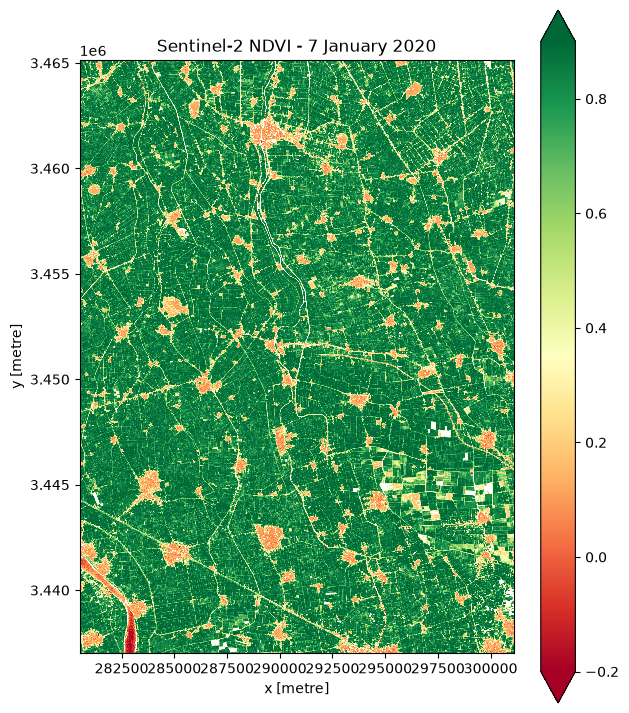

In [15]:
# 1. Offset (read it from the image, do not hard-code it)
baseline = float(test_items[0].properties["s2:processing_baseline"])
offset = -1000.0 if baseline >= 4.0 else 0.0
print("baseline:", baseline, "| offset:", offset)

# 2. Keep only clear pixels (SCL classes 4, 5, 6, 7)
clear = ds.SCL.isin([4, 5, 6, 7])

# 3. Reflectance (DN = 0 means no data)
red = ((ds.B04 + offset) / 10000).where((ds.B04 > 0) & clear)
nir = ((ds.B08 + offset) / 10000).where((ds.B08 > 0) & clear)

# 4. NDVI
ndvi = ((nir - red) / (nir + red)).compute()     # this is where the data is really read

print("NDVI min:", float(ndvi.min()), "| max:", float(ndvi.max()))
print("Clear pixels: {:.1f}%".format(float(clear.mean()) * 100))

fig, ax = plt.subplots(figsize=(7, 9))
ndvi.plot(ax=ax, vmin=-0.2, vmax=0.9, cmap="RdYlGn")
ax.set_title("Sentinel-2 NDVI - 7 January 2020")
ax.set_aspect("equal")
plt.show()

### A5 - Check the 0.3 threshold

We said: a pixel is not farmland if its NDVI never goes above 0.3.
0.3 was only a starting guess. Here we look at the real values to check it.
A histogram of farmland and villages should show two separate groups.

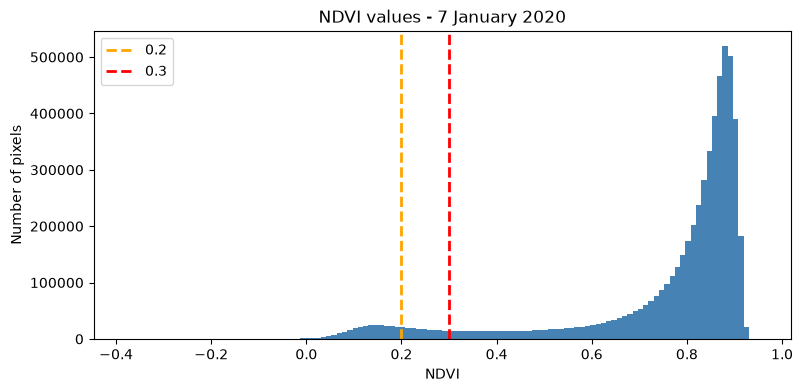

Pixels below 0.2: 4.9%
Pixels below 0.3: 7.6%
Pixels above 0.6: 84.9%


In [16]:
vals = ndvi.values.ravel()
vals = vals[~np.isnan(vals)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(vals, bins=120, color="steelblue")
for t, c in [(0.2, "orange"), (0.3, "red")]:
    ax.axvline(t, color=c, ls="--", lw=2, label=f"{t}")
ax.set_xlabel("NDVI")
ax.set_ylabel("Number of pixels")
ax.set_title("NDVI values - 7 January 2020")
ax.legend()
plt.show()

print("Pixels below 0.2: {:.1f}%".format((vals < 0.2).mean() * 100))
print("Pixels below 0.3: {:.1f}%".format((vals < 0.3).mean() * 100))
print("Pixels above 0.6: {:.1f}%".format((vals > 0.6).mean() * 100))

### A6 - One month, with timing

Before we run 108 months, we measure how long one month takes.
We also handle the offset correctly: we read the baseline of every image date,
because the offset changes in the middle of January 2022.

In [17]:
import time
import xarray as xr

def monthly_max_ndvi(year, month, res=10, max_cloud=80):
    """Max NDVI of the clear images in one month, for our area."""
    start = f"{year}-{month:02d}-01"
    end = (pd.Timestamp(start) + pd.offsets.MonthEnd(1)).strftime("%Y-%m-%d")

    items = catalog.search(collections=["sentinel-2-l2a"],
                           bbox=[W, S, E, N],
                           datetime=f"{start}/{end}").item_collection()
    items = [i for i in items if i.properties.get("eo:cloud_cover", 100) < max_cloud]
    if len(items) == 0:
        return None, 0

    ds = odc.stac.load(items, bands=["B04", "B08", "SCL"], bbox=[W, S, E, N],
                       crs="EPSG:32636", resolution=res,
                       groupby="solar_day", chunks={})

    # offset per date (read from the images, not hard-coded)
    bl = {}
    for i in items:
        d = pd.Timestamp(i.datetime.date())
        bl[d] = max(bl.get(d, 0), float(i.properties["s2:processing_baseline"]))
    times = pd.to_datetime(ds.time.values).normalize()
    off = xr.DataArray([-1000.0 if bl.get(t, 0) >= 4.0 else 0.0 for t in times],
                       coords={"time": ds.time}, dims="time")

    clear = ds.SCL.isin([4, 5, 6, 7])
    red = ((ds.B04 + off) / 10000).where((ds.B04 > 0) & clear)
    nir = ((ds.B08 + off) / 10000).where((ds.B08 > 0) & clear)
    ndvi = (nir - red) / (nir + red)
    return ndvi.max(dim="time").compute(), len(ds.time)

t0 = time.time()
m, n = monthly_max_ndvi(2020, 1)
secs = time.time() - t0

print(f"dates used: {n} | time: {secs:.0f} seconds")
print(f"108 months would take about {secs * 108 / 60:.0f} minutes")
print("shape:", m.shape, "| valid pixels: {:.1f}%".format(float(m.notnull().mean()) * 100))

c:\Users\musta\AppData\Local\Programs\Python\Python314\Lib\site-packages\rasterio\warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


dates used: 12 | time: 757 seconds
108 months would take about 1362 minutes
shape: (2812, 2058) | valid pixels: 99.9%


In [18]:
import os
os.makedirs("../data/raw/s2_monthly", exist_ok=True)

def monthly_max_ndvi(year, month, res=20, top_n=6, max_cloud=80):
    """Max NDVI of the clearest images in one month. Saves the result so we can resume."""
    out_path = f"../data/raw/s2_monthly/ndvi_{year}_{month:02d}.nc"
    if os.path.exists(out_path):                      # already done before
        return xr.open_dataarray(out_path), -1

    start = f"{year}-{month:02d}-01"
    end = (pd.Timestamp(start) + pd.offsets.MonthEnd(1)).strftime("%Y-%m-%d")

    items = catalog.search(collections=["sentinel-2-l2a"],
                           bbox=[W, S, E, N],
                           datetime=f"{start}/{end}").item_collection()
    items = [i for i in items if i.properties.get("eo:cloud_cover", 100) < max_cloud]
    if len(items) == 0:
        return None, 0

    # keep only the clearest dates
    items = sorted(items, key=lambda i: i.properties.get("eo:cloud_cover", 100))
    keep_dates = []
    for i in items:
        d = i.datetime.date()
        if d not in keep_dates:
            keep_dates.append(d)
        if len(keep_dates) >= top_n:
            break
    items = [i for i in items if i.datetime.date() in keep_dates]

    ds = odc.stac.load(items, bands=["B04", "B08", "SCL"], bbox=[W, S, E, N],
                       crs="EPSG:32636", resolution=res,
                       groupby="solar_day", chunks={})

    bl = {}
    for i in items:
        d = pd.Timestamp(i.datetime.date())
        bl[d] = max(bl.get(d, 0), float(i.properties["s2:processing_baseline"]))
    times = pd.to_datetime(ds.time.values).normalize()
    off = xr.DataArray([-1000.0 if bl.get(t, 0) >= 4.0 else 0.0 for t in times],
                       coords={"time": ds.time}, dims="time")

    clear = ds.SCL.isin([4, 5, 6, 7])
    red = ((ds.B04 + off) / 10000).where((ds.B04 > 0) & clear)
    nir = ((ds.B08 + off) / 10000).where((ds.B08 > 0) & clear)
    ndvi = ((nir - red) / (nir + red)).max(dim="time").compute()

    ndvi.name = "ndvi"
    ndvi.to_netcdf(out_path)                          # save, so we never redo this month
    return ndvi, len(ds.time)

# Test on one month with the new settings
t0 = time.time()
m, n = monthly_max_ndvi(2020, 1)
print(f"dates: {n} | time: {time.time() - t0:.0f} s | shape: {m.shape}")

c:\Users\musta\AppData\Local\Programs\Python\Python314\Lib\site-packages\rasterio\warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


dates: 6 | time: 716 s | shape: (1406, 1030)


In [19]:
t0 = time.time()
m2, n2 = monthly_max_ndvi(2020, 2, res=20, top_n=2)
print(f"dates: {n2} | time: {time.time() - t0:.0f} s")

dates: 2 | time: 26 s
